In [10]:
import numpy as np 
import tensorflow as tf 
import matplotlib.pyplot as plt
import pandas as pd 
import os 
import seaborn as sns
from sklearn.model_selection import train_test_split
from  sklearn.metrics import accuracy_score, classification_report, confusion_matrix 
from sklearn.preprocessing import StandardScaler
SEED = 42 
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [11]:
NUM_SAMPLES_PER_CLASS = 1500
SIGNAL_LENGTH = 128

CLASS_NAMES = [
    "OMA",
    "NOMA Low",
    "NOMA Medium",
    "NOMA High"
]

def generate_qpsk(n):
    bits = np.random.randint(0, 2, (n, 2))

    symbols = (
        (1 - 2 * bits[:, 0]) +
        1j * (1 - 2 * bits[:, 1])
    ) / np.sqrt(2)

    return symbols


def generate_signal(class_id):

    s1 = generate_qpsk(SIGNAL_LENGTH)
    s2 = generate_qpsk(SIGNAL_LENGTH)

    if class_id == 0:
        alpha = 0.0

    elif class_id == 1:
        alpha = 0.15

    elif class_id == 2:
        alpha = 0.35

    else:
        alpha = 0.50

    signal = (
        np.sqrt(1 - alpha) * s1 +
        np.sqrt(alpha) * s2
    )

    snr_db = np.random.uniform(15, 25)
    snr_linear = 10 ** (snr_db / 10)

    noise_power = 1 / snr_linear

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(SIGNAL_LENGTH) +
        1j * np.random.randn(SIGNAL_LENGTH)
    )

    received = signal + noise

    iq = np.stack(
        [received.real, received.imag],
        axis=-1
    )

    return iq.astype(np.float32)


X = []
y = []

for class_id in range(4):

    for _ in range(NUM_SAMPLES_PER_CLASS):

        X.append(generate_signal(class_id))
        y.append(class_id)

X = np.array(X)
y = np.array(y)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", CLASS_NAMES)

Dataset shape: (6000, 128, 2)
Labels shape: (6000,)
Classes: ['OMA', 'NOMA Low', 'NOMA Medium', 'NOMA High']


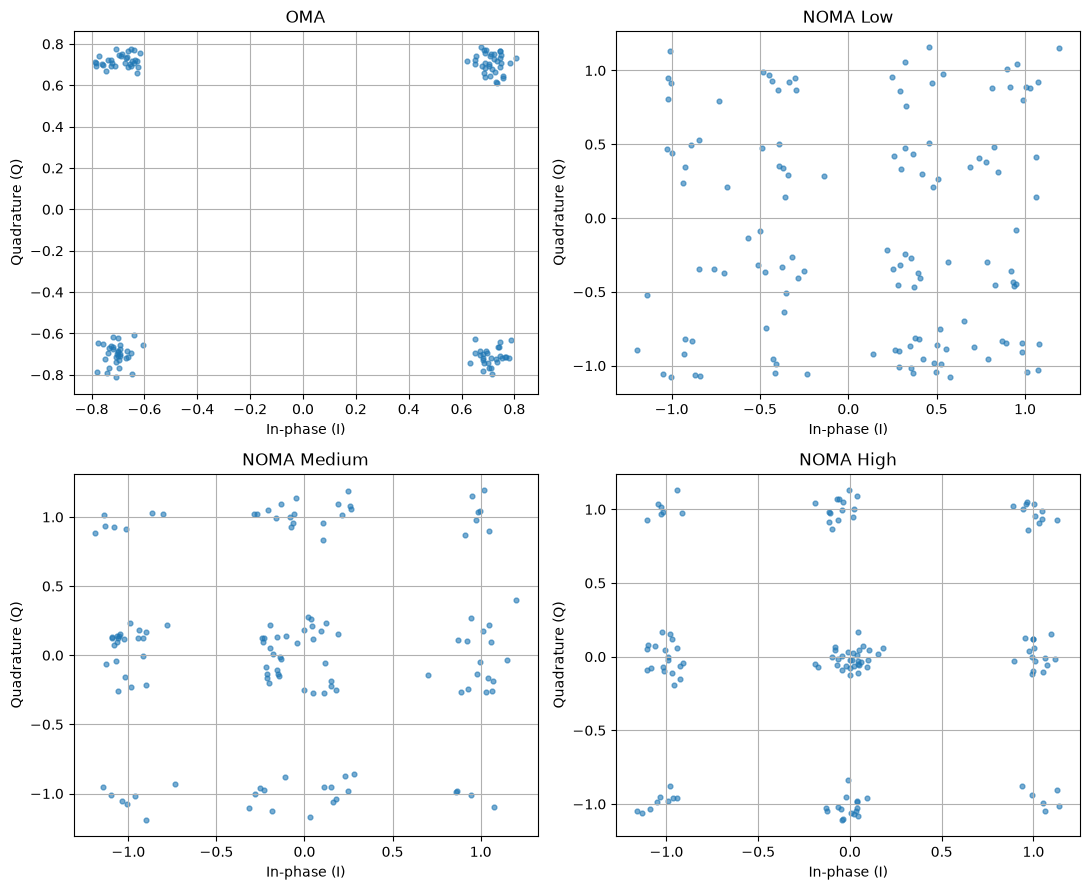

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for class_id, ax in enumerate(axes.flat):

    sample = X[y == class_id][0]

    ax.scatter(
        sample[:, 0],
        sample[:, 1],
        s=12,
        alpha=0.6
    )

    ax.set_title(CLASS_NAMES[class_id])
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=SEED, stratify=y)
print("Training set shape:", X_train.shape, y_train.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (4800, 128, 2) (4800,)
Test set shape: (1200, 128, 2) (1200,)


In [14]:
from tensorflow.keras import layers, models
inputs = layers.Input(shape=(SIGNAL_LENGTH, 2))
x= layers.Conv1D(32, 5, activation='relu')(inputs)
x= layers.MaxPooling1D(2)(x)
x= layers.Conv1D(64, 3, activation='relu')(x)
x = layers.MaxPooling1D(2)(x) 
x = layers.Conv1D(128, 3, activation='relu')(x)
x = layers.GlobalAveragePooling1D()(x)
embeddings = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(len(CLASS_NAMES), activation='softmax')(embeddings)

model = models.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 2)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 124, 32)        │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 62, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 60, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 28, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,780 (155.39 KB)

 Trainable params: 39,780 (155.39 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.2479 - loss: 1.3882 - val_accuracy: 0.2521 - val_loss: 1.3874
Epoch 2/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2428 - loss: 1.3868 - val_accuracy: 0.2521 - val_loss: 1.3861
Epoch 3/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2921 - loss: 1.3676 - val_accuracy: 0.4917 - val_loss: 1.1628
Epoch 4/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8049 - loss: 0.4754 - val_accuracy: 0.8646 - val_loss: 0.2808
Epoch 5/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9130 - loss: 0.2126 - val_accuracy: 0.9083 - val_loss: 0.1989
Epoch 6/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9396 - loss: 0.1568 - val_accuracy: 0.9250 - val_loss: 0.1551
Epoch 7/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9528 - loss: 0.1263 - val_accuracy: 0.9458 - val_loss: 0.1262
Epoch 8/20
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9676 - loss: 0.0944 - val_accuracy: 0.

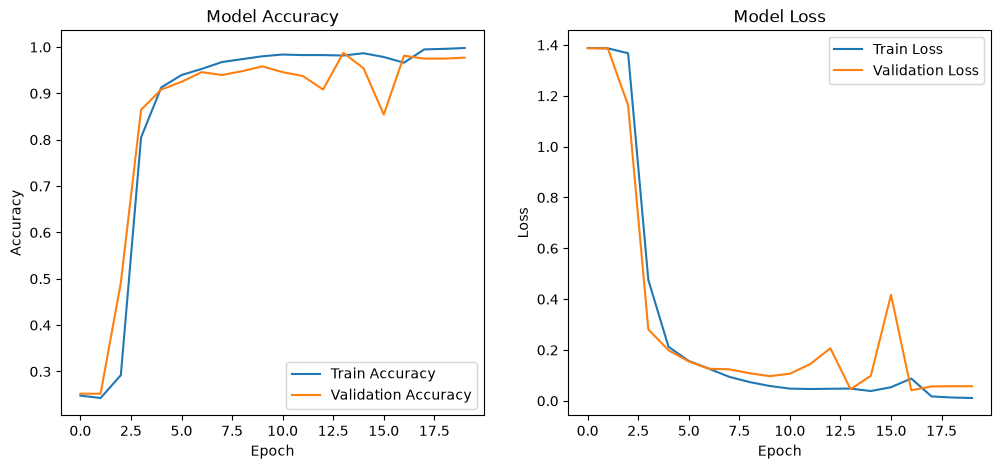

In [15]:
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1) 
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [16]:
zero_prob = model.predict(X_test,verbose = 0 )
zero_pred = np.argmax(zero_prob, axis=1) 
zero_acc = accuracy_score(y_test, zero_pred)
print(f"Zero-shot accuracy: {zero_acc:.4f}")
print(classification_report(y_test, zero_pred, target_names=CLASS_NAMES))

Zero-shot accuracy: 0.9900
              precision    recall  f1-score   support

         OMA       1.00      1.00      1.00       300
    NOMA Low       1.00      1.00      1.00       300
 NOMA Medium       1.00      0.96      0.98       300
   NOMA High       0.96      1.00      0.98       300

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200



In [17]:
embedding_model = models.Model(inputs=inputs, outputs=embeddings) 
train_embeddings = embedding_model.predict(X_train, verbose=0) 
test_embeddings = embedding_model.predict(X_test, verbose=0)
print("Train embeddings shape:", train_embeddings.shape) 
print("Test embeddings shape:", test_embeddings.shape)

Train embeddings shape: (4800, 64)
Test embeddings shape: (1200, 64)


In [18]:
def k_shot_predict(k,seed= 42):
       rng = np.random.default_rng(seed) 
       prototypes = [] 
       for class_id in range(len(CLASS_NAMES)): 
              indices = np.where(y_train == class_id)[0] 
              selected_indices = rng.choice(indices, size=k, replace=False)
              prototypes.append(np.mean(train_embeddings[selected_indices], axis=0))
       prototypes = np.array(prototypes) 

       distances = np.linalg.norm(test_embeddings[:, np.newaxis] - prototypes, axis=2)
       predictions = np.argmin(distances, axis=1)
       return predictions
one_pred = k_shot_predict(k = 1)
one_acc = accuracy_score(y_test, one_pred) 
print(f"One-shot accuracy: {one_acc:.4f}")
print(classification_report(y_test, one_pred, target_names=CLASS_NAMES))


One-shot accuracy: 0.9675
              precision    recall  f1-score   support

         OMA       1.00      1.00      1.00       300
    NOMA Low       1.00      1.00      1.00       300
 NOMA Medium       0.88      1.00      0.94       300
   NOMA High       1.00      0.87      0.93       300

    accuracy                           0.97      1200
   macro avg       0.97      0.97      0.97      1200
weighted avg       0.97      0.97      0.97      1200

